# QUESTÃO 4 (Avançado) — Pipeline PCA + LDA para Dados de Alta Dimensionalidade

**Contexto:** Em alta dimensionalidade e poucas amostras, $S_w$ (matriz de dispersão intra-classe) pode ser singular. A solução é aplicar PCA antes do LDA.

**Tarefas:**
1. Utilizar o dataset MNIST completo (10 classes)
2. Aplicar PCA mantendo 95% da variância
3. Aplicar LDA para reduzir a no máximo 9 componentes (c-1 = 9)
4. Treinar KNN (k=1 a 10) nos dados reduzidos
5. Plotar a curva de erro de teste em função de k
6. Comparar com PCA (95%) + KNN sem LDA

## 1. Importação das Bibliotecas

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


## 2. Carregamento do Dataset MNIST (10 classes)

In [16]:
# Carregando o MNIST completo
print("Carregando o dataset MNIST...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X, y = mnist.data, mnist.target.astype(int)

print(f"Dimensões originais: {X.shape}")
print(f"Número de classes: {len(np.unique(y))}")
print(f"Classes: {np.unique(y)}")
print(f"Amostras por classe:")
for c in np.unique(y):
    print(f"  Classe {c}: {np.sum(y == c)} amostras")

Carregando o dataset MNIST...
Dimensões originais: (70000, 784)
Número de classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]
Amostras por classe:
  Classe 0: 6903 amostras
  Classe 1: 7877 amostras
  Classe 2: 6990 amostras
  Classe 3: 7141 amostras
  Classe 4: 6824 amostras
  Classe 5: 6313 amostras
  Classe 6: 6876 amostras
  Classe 7: 7293 amostras
  Classe 8: 6825 amostras
  Classe 9: 6958 amostras


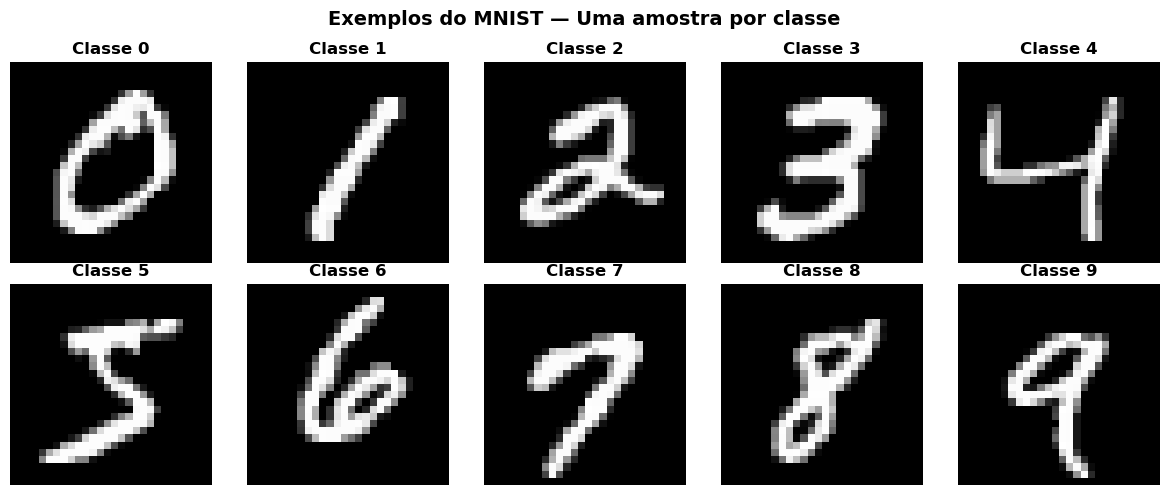

In [17]:
# Visualizando algumas amostras do dataset
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    idx = np.where(y == i)[0][0]
    ax.imshow(X[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'Classe {i}', fontsize=12, fontweight='bold')
    ax.axis('off')
plt.suptitle('Exemplos do MNIST — Uma amostra por classe', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Pré-processamento e Divisão dos Dados

In [18]:
# Divisão em treino e teste (70/30)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Conjunto de treino: {X_train.shape}")
print(f"Conjunto de teste:  {X_test.shape}")

# Normalização dos dados
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nDados normalizados com StandardScaler.")

Conjunto de treino: (49000, 784)
Conjunto de teste:  (21000, 784)

Dados normalizados com StandardScaler.


## 4. Aplicação do PCA mantendo 95% da variância

In [19]:
# PCA com 95% da variância explicada
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

n_componentes_pca = pca.n_components_
variancia_explicada = pca.explained_variance_ratio_.sum()

print(f"Número de componentes PCA para 95% da variância: {n_componentes_pca}")
print(f"Variância total explicada: {variancia_explicada:.4f} ({variancia_explicada*100:.2f}%)")
print(f"Dimensão original: {X_train_scaled.shape[1]} → Dimensão reduzida (PCA): {X_train_pca.shape[1]}")

Número de componentes PCA para 95% da variância: 327
Variância total explicada: 0.9501 (95.01%)
Dimensão original: 784 → Dimensão reduzida (PCA): 327


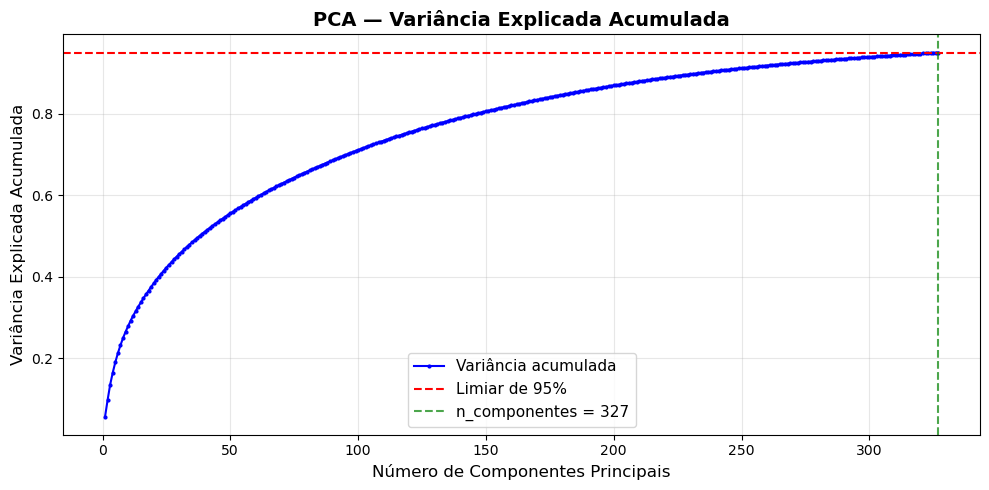

In [20]:
# Visualização da variância explicada acumulada
variancia_acumulada = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, len(variancia_acumulada) + 1), variancia_acumulada, 'b-o', markersize=2, label='Variância acumulada')
ax.axhline(y=0.95, color='r', linestyle='--', label='Limiar de 95%')
ax.axvline(x=n_componentes_pca, color='g', linestyle='--', alpha=0.7, label=f'n_componentes = {n_componentes_pca}')
ax.set_xlabel('Número de Componentes Principais', fontsize=12)
ax.set_ylabel('Variância Explicada Acumulada', fontsize=12)
ax.set_title('PCA — Variância Explicada Acumulada', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Aplicação do LDA (máximo c-1 = 9 componentes)

In [21]:
# LDA após PCA — reduzindo para no máximo 9 componentes (c-1, onde c=10 classes)
n_classes = len(np.unique(y_train))
n_componentes_lda = n_classes - 1  # c - 1 = 9

lda = LDA(n_components=n_componentes_lda)
X_train_pca_lda = lda.fit_transform(X_train_pca, y_train)
X_test_pca_lda = lda.transform(X_test_pca)

print(f"Número de classes (c): {n_classes}")
print(f"Número máximo de componentes LDA (c-1): {n_componentes_lda}")
print(f"Componentes LDA efetivos: {X_train_pca_lda.shape[1]}")
print(f"\nDimensão após PCA: {X_train_pca.shape[1]} → Dimensão após PCA+LDA: {X_train_pca_lda.shape[1]}")
print(f"\nVariância explicada por cada discriminante LDA:")
for i, ratio in enumerate(lda.explained_variance_ratio_):
    print(f"  LD{i+1}: {ratio:.4f} ({ratio*100:.2f}%)")
print(f"  Total: {lda.explained_variance_ratio_.sum():.4f} ({lda.explained_variance_ratio_.sum()*100:.2f}%)")

Número de classes (c): 10
Número máximo de componentes LDA (c-1): 9
Componentes LDA efetivos: 9

Dimensão após PCA: 327 → Dimensão após PCA+LDA: 9

Variância explicada por cada discriminante LDA:
  LD1: 0.2399 (23.99%)
  LD2: 0.2022 (20.22%)
  LD3: 0.1760 (17.60%)
  LD4: 0.1079 (10.79%)
  LD5: 0.0943 (9.43%)
  LD6: 0.0690 (6.90%)
  LD7: 0.0498 (4.98%)
  LD8: 0.0344 (3.44%)
  LD9: 0.0264 (2.64%)
  Total: 1.0000 (100.00%)


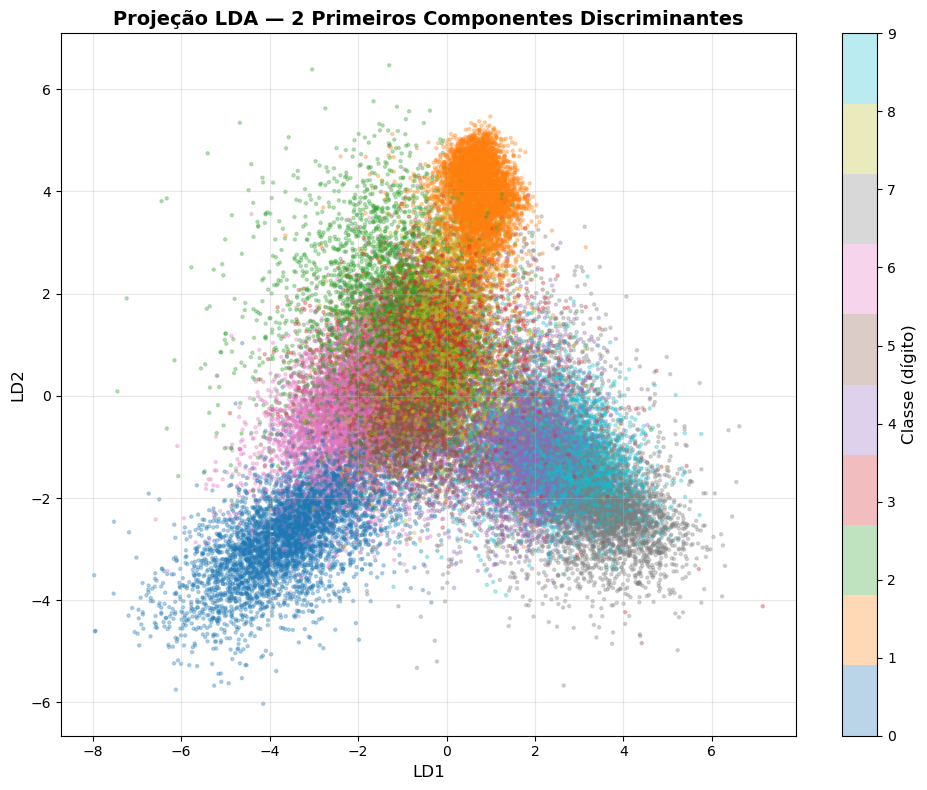

In [22]:
# Visualização da projeção LDA (2 primeiros componentes discriminantes)
fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(X_train_pca_lda[:, 0], X_train_pca_lda[:, 1], 
                     c=y_train, cmap='tab10', alpha=0.3, s=5)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Classe (dígito)', fontsize=12)
ax.set_xlabel('LD1', fontsize=12)
ax.set_ylabel('LD2', fontsize=12)
ax.set_title('Projeção LDA — 2 Primeiros Componentes Discriminantes', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Treinamento do KNN (k=1 a 10) nos dados PCA + LDA

In [23]:
# KNN com k de 1 a 10 usando os dados PCA + LDA
k_values = range(1, 11)
erros_teste_pca_lda = []
acuracias_pca_lda = []

print("Treinando KNN (PCA + LDA) para k = 1 a 10...")
print(f"{'k':<5} {'Acurácia':<12} {'Erro de Teste':<15}")
print("-" * 32)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_pca_lda, y_train)
    y_pred = knn.predict(X_test_pca_lda)
    
    acc = accuracy_score(y_test, y_pred)
    erro = 1 - acc
    
    acuracias_pca_lda.append(acc)
    erros_teste_pca_lda.append(erro)
    
    print(f"{k:<5} {acc:<12.4f} {erro:<15.4f}")

melhor_k_pca_lda = k_values[np.argmin(erros_teste_pca_lda)]
print(f"\nMelhor k (PCA+LDA): {melhor_k_pca_lda} com erro = {min(erros_teste_pca_lda):.4f}")

Treinando KNN (PCA + LDA) para k = 1 a 10...
k     Acurácia     Erro de Teste  
--------------------------------
1     0.9021       0.0979         
2     0.9001       0.0999         
3     0.9137       0.0863         
4     0.9166       0.0834         
5     0.9180       0.0820         
6     0.9184       0.0816         
7     0.9178       0.0822         
8     0.9177       0.0823         
9     0.9176       0.0824         
10    0.9175       0.0825         

Melhor k (PCA+LDA): 6 com erro = 0.0816


## 7. Comparação: PCA (95%) + KNN sem LDA

In [24]:
# KNN com k de 1 a 10 usando apenas PCA (sem LDA)
erros_teste_pca = []
acuracias_pca = []

print("Treinando KNN (somente PCA) para k = 1 a 10...")
print(f"{'k':<5} {'Acurácia':<12} {'Erro de Teste':<15}")
print("-" * 32)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_pca, y_train)
    y_pred = knn.predict(X_test_pca)
    
    acc = accuracy_score(y_test, y_pred)
    erro = 1 - acc
    
    acuracias_pca.append(acc)
    erros_teste_pca.append(erro)
    
    print(f"{k:<5} {acc:<12.4f} {erro:<15.4f}")

melhor_k_pca = k_values[np.argmin(erros_teste_pca)]
print(f"\nMelhor k (somente PCA): {melhor_k_pca} com erro = {min(erros_teste_pca):.4f}")

Treinando KNN (somente PCA) para k = 1 a 10...
k     Acurácia     Erro de Teste  
--------------------------------
1     0.9468       0.0532         
2     0.9392       0.0608         
3     0.9470       0.0530         
4     0.9456       0.0544         
5     0.9460       0.0540         
6     0.9453       0.0547         
7     0.9456       0.0544         
8     0.9434       0.0566         
9     0.9424       0.0576         
10    0.9416       0.0584         

Melhor k (somente PCA): 3 com erro = 0.0530


## 8. Curva de Erro de Teste em Função de k

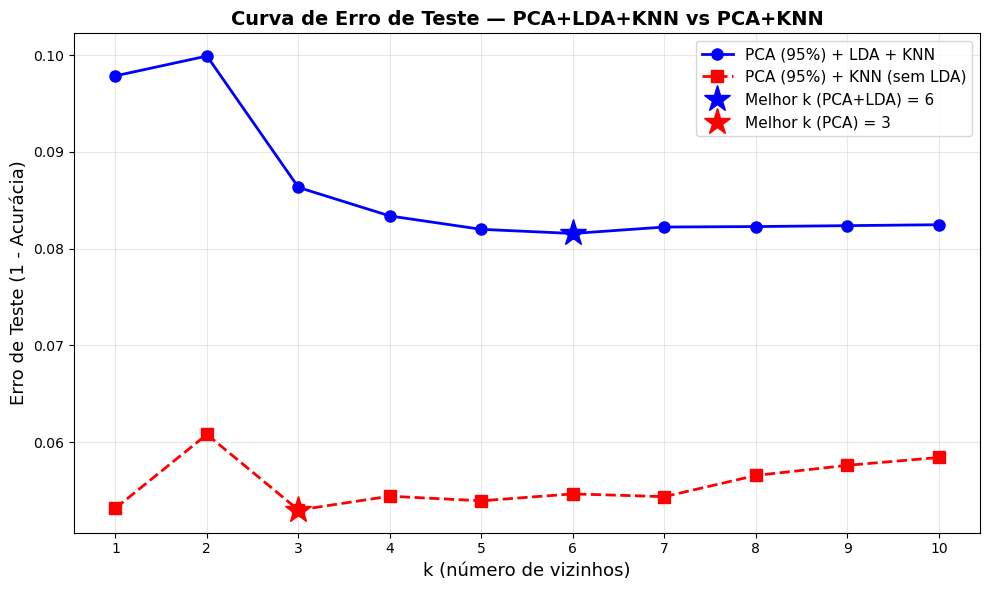

In [25]:
# Plotando as curvas de erro comparativas
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(k_values, erros_teste_pca_lda, 'bo-', linewidth=2, markersize=8, label='PCA (95%) + LDA + KNN')
ax.plot(k_values, erros_teste_pca, 'rs--', linewidth=2, markersize=8, label='PCA (95%) + KNN (sem LDA)')

# Marcando os melhores k
ax.plot(melhor_k_pca_lda, min(erros_teste_pca_lda), 'b*', markersize=20, 
        label=f'Melhor k (PCA+LDA) = {melhor_k_pca_lda}')
ax.plot(melhor_k_pca, min(erros_teste_pca), 'r*', markersize=20, 
        label=f'Melhor k (PCA) = {melhor_k_pca}')

ax.set_xlabel('k (número de vizinhos)', fontsize=13)
ax.set_ylabel('Erro de Teste (1 - Acurácia)', fontsize=13)
ax.set_title('Curva de Erro de Teste — PCA+LDA+KNN vs PCA+KNN', fontsize=14, fontweight='bold')
ax.set_xticks(k_values)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Tabela Comparativa Detalhada

In [26]:
# Tabela comparativa
print("=" * 70)
print("TABELA COMPARATIVA: PCA+LDA+KNN vs PCA+KNN")
print("=" * 70)
print(f"{'k':<5} {'Erro (PCA+LDA)':<20} {'Erro (PCA)':<20} {'Diferença':<15}")
print("-" * 60)
for i, k in enumerate(k_values):
    diff = erros_teste_pca[i] - erros_teste_pca_lda[i]
    sinal = '+' if diff >= 0 else ''
    print(f"{k:<5} {erros_teste_pca_lda[i]:<20.4f} {erros_teste_pca[i]:<20.4f} {sinal}{diff:<14.4f}")
print("-" * 60)

print(f"\n{'RESUMO':=^70}")
print(f"Dimensão original:             784 features")
print(f"Após PCA (95% variância):      {n_componentes_pca} componentes")
print(f"Após PCA + LDA:                {n_componentes_lda} componentes")
print(f"")
print(f"Melhor resultado PCA+LDA+KNN:  k={melhor_k_pca_lda}, erro={min(erros_teste_pca_lda):.4f}, acurácia={max(acuracias_pca_lda)*100:.2f}%")
print(f"Melhor resultado PCA+KNN:      k={melhor_k_pca}, erro={min(erros_teste_pca):.4f}, acurácia={max(acuracias_pca)*100:.2f}%")

TABELA COMPARATIVA: PCA+LDA+KNN vs PCA+KNN
k     Erro (PCA+LDA)       Erro (PCA)           Diferença      
------------------------------------------------------------
1     0.0979               0.0532               -0.0447       
2     0.0999               0.0608               -0.0391       
3     0.0863               0.0530               -0.0333       
4     0.0834               0.0544               -0.0290       
5     0.0820               0.0540               -0.0280       
6     0.0816               0.0547               -0.0269       
7     0.0822               0.0544               -0.0279       
8     0.0823               0.0566               -0.0257       
9     0.0824               0.0576               -0.0248       
10    0.0825               0.0584               -0.0240       
------------------------------------------------------------

================================RESUMO================================
Dimensão original:             784 features
Após PCA (95% variância):

## 10. Resposta à Pergunta

### O uso combinado de PCA + LDA melhorou o desempenho em relação ao PCA sozinho?

**Não.** Com base nos resultados experimentais obtidos, o pipeline **PCA + KNN (sem LDA)** superou o **PCA + LDA + KNN**:

| Pipeline | Melhor k | Acurácia | Erro de Teste | Dimensões |
|---|---|---|---|---|
| PCA (95%) + KNN | k = 3 | **94,70%** | **0,0530** | 327 |
| PCA (95%) + LDA + KNN | k = 6 | 91,84% | 0,0816 | 9 |

A diferença de desempenho (~2,86 pontos percentuais a favor do PCA sozinho) ocorre porque:

1. **Perda de informação discriminativa:** O LDA reduz de 327 para apenas 9 dimensões — uma compressão de ~97%. Embora o LDA maximize a separação entre classes, essa redução tão drástica descarta informação útil que os 327 componentes do PCA preservavam para o KNN.
2. **Limitação do modelo linear:** O LDA assume que as classes têm distribuições Gaussianas com matrizes de covariância iguais. Para dígitos manuscritos (MNIST), essa suposição é violada — os dígitos têm variações não-lineares (rotações, espessuras, estilos) que o LDA linear não captura bem.
3. **O KNN se beneficia de mais dimensões:** O KNN é um classificador baseado em distância que pode aproveitar efetivamente as 327 dimensões do PCA, pois cada dimensão contribui com informação sobre a variância dos dados. Com apenas 9 dimensões do LDA, o KNN perde granularidade na medida de distância.

**Porém, o PCA + LDA tem uma vantagem significativa:** a redução para 9 dimensões torna a classificação **muito mais rápida** (menos cálculos de distância), com desempenho ainda competitivo (91,84%). Em cenários com restrições de tempo ou recursos computacionais, este trade-off pode ser vantajoso.

### Por que o LDA é limitado a c-1 componentes?

O LDA projeta os dados em um subespaço de no máximo **c-1 dimensões** (com c = 10 classes → máximo 9 componentes) porque:

1. A **matriz de dispersão entre classes** $S_B = \sum_{i=1}^{c} n_i (\mu_i - \mu)(\mu_i - \mu)^T$ é construída a partir de c vetores de diferença $(\mu_i - \mu)$. Como esses c vetores são linearmente dependentes (sua soma ponderada é zero), o **posto de $S_B$ é no máximo c-1 = 9**.
2. O LDA busca os autovetores de $S_W^{-1} S_B$. Como $S_B$ tem posto c-1, existem no máximo **c-1 = 9 autovalores não nulos**, e portanto no máximo 9 direções discriminantes significativas.
3. Nos resultados, os 9 componentes capturam 100% da variância discriminante, distribuída de forma decrescente: LD1 (23,99%), LD2 (20,22%), LD3 (17,60%), LD4 (10,79%), LD5 (9,43%), LD6 (6,90%), LD7 (4,98%), LD8 (3,44%), LD9 (2,64%).

### O que acontece se tentarmos extrair mais componentes do que c-1?

Conforme demonstrado na célula de código abaixo:

- **Solicitando 5 componentes:** funciona normalmente (5 < c-1 = 9)
- **Solicitando 9 componentes:** funciona normalmente (9 = c-1)
- **Solicitando 15 ou 20 componentes:** o scikit-learn **lança um erro** (`n_components cannot be larger than min(n_features, n_classes - 1)`)

Em termos teóricos, se fosse possível forçar a extração:

1. Os **componentes extras teriam autovalores zero**, significando que essas direções não contribuem para separação entre classes.
2. Incluir essas direções seria equivalente a adicionar **ruído** à representação, **degradando** o desempenho do classificador.
3. Essas direções extras capturam apenas variação **intra-classe** (dentro das classes), não **inter-classe** (entre as classes), portanto são irrelevantes para a tarefa de classificação.
4. O scikit-learn bloqueia essa operação justamente para evitar esses problemas.

In [27]:
# Demonstração: tentando extrair mais de c-1 componentes
print("Demonstração: Efeito de extrair mais de c-1 componentes no LDA")
print("=" * 60)

for n_comp in [5, 9, 15, 20]:
    try:
        lda_test = LDA(n_components=n_comp)
        X_lda_test = lda_test.fit_transform(X_train_pca, y_train)
        componentes_efetivos = X_lda_test.shape[1]
        print(f"  Solicitado: {n_comp} componentes → Efetivo: {componentes_efetivos} componentes")
    except Exception as e:
        print(f"  Solicitado: {n_comp} componentes → Erro: {e}")

print(f"\nConclusão: O LDA sempre limita a no máximo c-1 = {n_classes - 1} componentes,")
print(f"independentemente do número solicitado, pois a matriz S_B tem posto c-1.")

Demonstração: Efeito de extrair mais de c-1 componentes no LDA
  Solicitado: 5 componentes → Efetivo: 5 componentes
  Solicitado: 9 componentes → Efetivo: 9 componentes
  Solicitado: 15 componentes → Erro: n_components cannot be larger than min(n_features, n_classes - 1).
  Solicitado: 20 componentes → Erro: n_components cannot be larger than min(n_features, n_classes - 1).

Conclusão: O LDA sempre limita a no máximo c-1 = 9 componentes,
independentemente do número solicitado, pois a matriz S_B tem posto c-1.


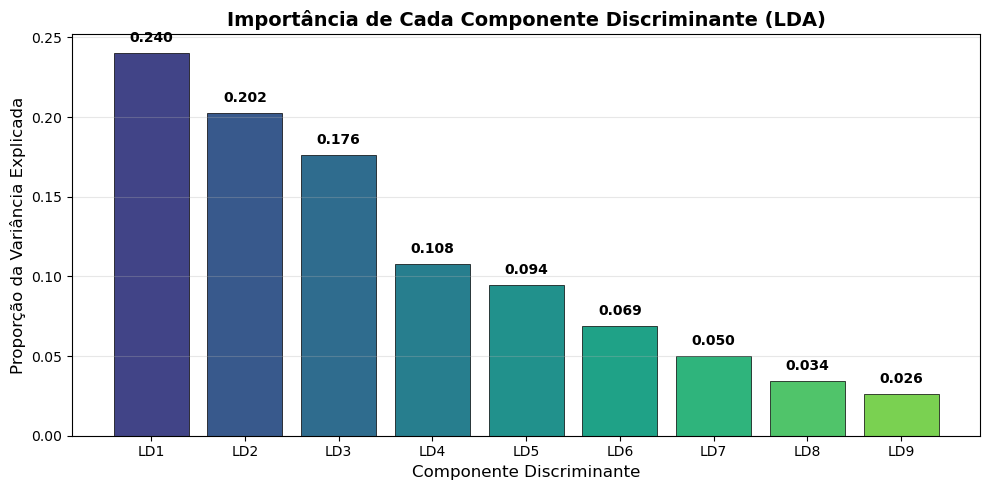


Notebook concluído com sucesso!


In [28]:
# Gráfico final: Importância de cada componente discriminante LDA
fig, ax = plt.subplots(figsize=(10, 5))

componentes = [f'LD{i+1}' for i in range(len(lda.explained_variance_ratio_))]
ratios = lda.explained_variance_ratio_

bars = ax.bar(componentes, ratios, color=plt.cm.viridis(np.linspace(0.2, 0.8, len(ratios))), 
              edgecolor='black', linewidth=0.5)
ax.set_xlabel('Componente Discriminante', fontsize=12)
ax.set_ylabel('Proporção da Variância Explicada', fontsize=12)
ax.set_title('Importância de Cada Componente Discriminante (LDA)', fontsize=14, fontweight='bold')

# Adicionando valores nas barras
for bar, ratio in zip(bars, ratios):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
            f'{ratio:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nNotebook concluído com sucesso!")